## Image Restoration

In [5]:
import numpy as np
import matplotlib.pyplot as plt

In [12]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Exercise
- noisy image f2를 불러오고 적절한 restoration(denoising)을 수행해보자.

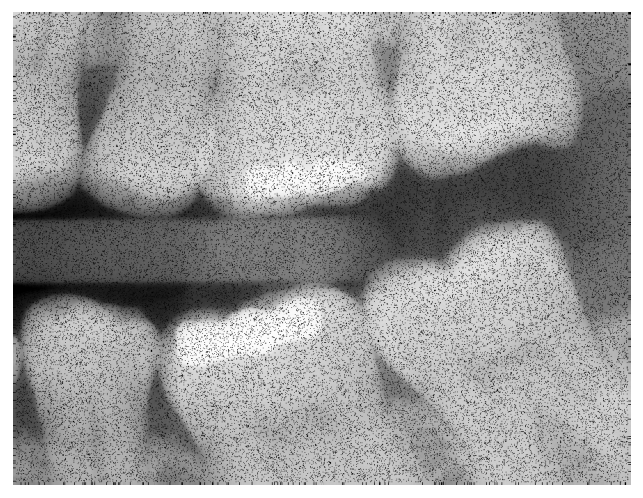

In [36]:
f2 = plt.imread('/content/drive/MyDrive/DIP4E/dentalXray-pepper-noise.tif')

plt.figure(dpi=128)
plt.imshow(f2,cmap='gray', vmin=0, vmax=255)
plt.axis('off')
plt.show()

In [37]:
print(f2.shape)
print(f2.dtype)
print(f2.min(), f2.max())

(680, 888)
uint8
0 255


In [38]:
f2 = f2.astype(float)
print(f2.dtype)

float64


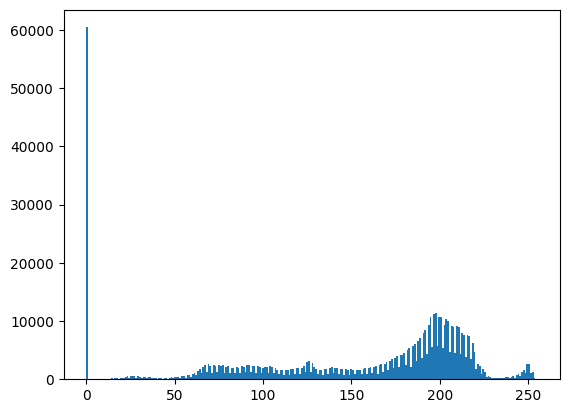

In [39]:
plt.hist(f2.ravel(), 256)
plt.show()

###1. Arithmetric Mean

In [40]:
SS = 3
ss = int((SS-1)/2)
f2_mean = np.zeros(np.shape(f2))

for x in range(ss, np.size(f2,0)-ss):
  for y in range(ss,np.size(f2, 1)-ss):
    Sxy = f2[x-ss:x-ss+SS, y-ss:y-ss+SS]
    f2_mean[x,y] = np.mean(Sxy)

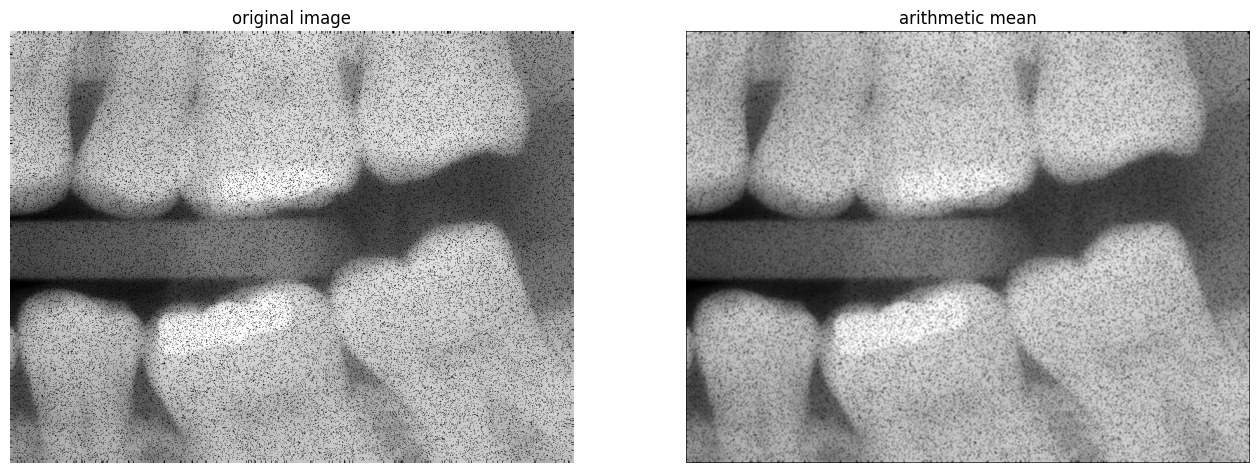

In [41]:
plt.figure(figsize=(16,9))
plt.subplot(121)
plt.imshow(f2,cmap='gray',aspect='equal')
plt.axis('off')
plt.title('original image')
plt.subplot(122)
plt.imshow(f2_mean,cmap='gray',aspect='equal', vmin=0, vmax=255)
plt.axis('off')
plt.title('arithmetic mean')
plt.show()

###2. Median

In [42]:
SS = 3
ss = int((SS-1)/2)
f2_median = np.zeros(np.shape(f2))

for x in range(ss,np.size(f2,0)-ss):
  for y in range(ss,np.size(f2,1)-ss):
    Sxy = f2[x-ss:x-ss+SS,y-ss:y-ss+SS]
    f2_median[x,y] = np.median(Sxy)

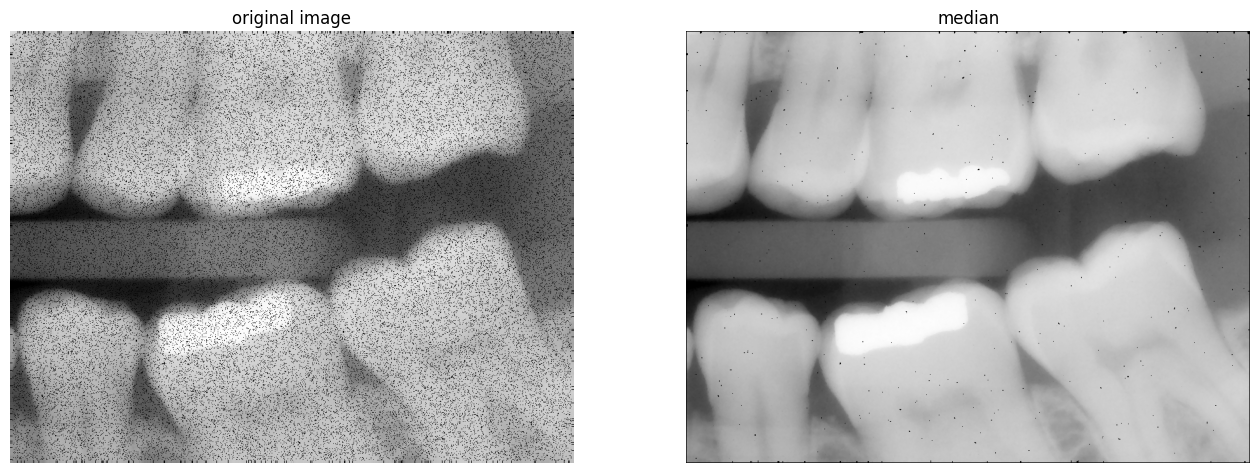

In [43]:
plt.figure(figsize=(16,9))
plt.subplot(121)
plt.imshow(f2,cmap='gray',aspect='equal')
plt.axis('off')
plt.title('original image')
plt.subplot(122)
plt.imshow(f2_median,cmap='gray',aspect='equal', vmin=0, vmax=255)
plt.axis('off')
plt.title('median')
plt.show()

###3. Adaptive local noise reduction

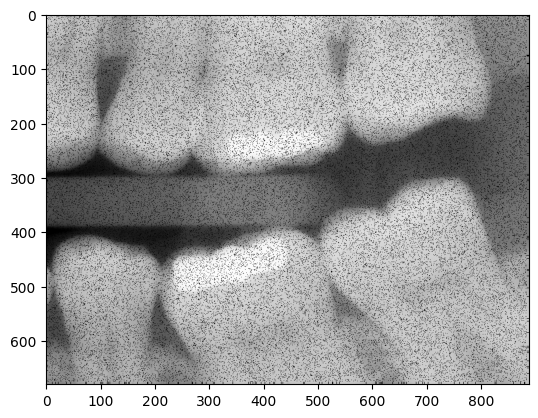

In [44]:
plt.imshow(f2, cmap='gray')
plt.show()

30.34090181029928


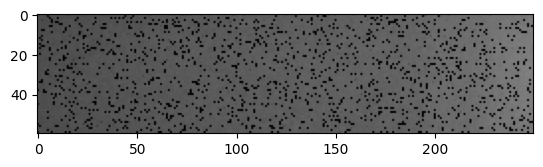

In [45]:
patch = f2[310:370, 50:300]
print(np.std(patch))
plt.imshow(patch, cmap='gray', vmin=0, vmax=255)
plt.show()

In [46]:
std_eta = 30
SS = 3

ss = int((SS-1)/2)
f2_amean = np.zeros(np.shape(f2))
for x in range(ss,np.size(f2,0)-ss):
  for y in range(ss,np.size(f2,1)-ss):
    Sxy = f2[x-ss:x-ss+SS,y-ss:y-ss+SS]
    var_Sxy = np.var(Sxy)
    if var_Sxy == 0:
      f2_amean[x,y] = f2[x,y]
    else:
      ratio = (std_eta*std_eta) / var_Sxy
      ratio = min(ratio, 1)
      f2_amean[x,y] = f2[x,y] - ratio*(f2[x,y]-np.mean(Sxy))

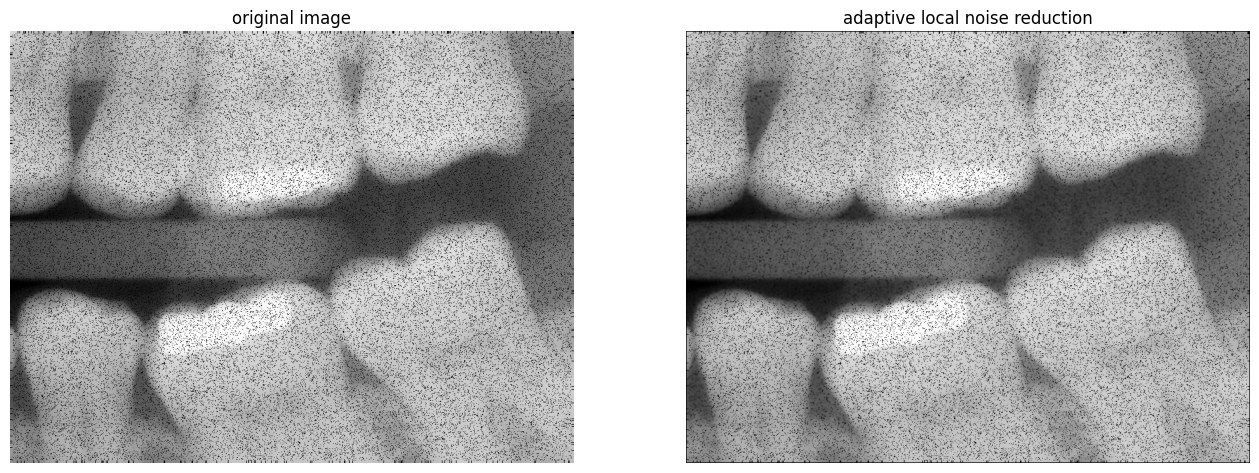

In [47]:
plt.figure(figsize=(16,9))
plt.subplot(121)
plt.imshow(f2,cmap='gray',aspect='equal')
plt.axis('off')
plt.title('original image')
plt.subplot(122)
plt.imshow(f2_amean,cmap='gray',aspect='equal', vmin=0, vmax=255)
plt.axis('off')
plt.title('adaptive local noise reduction')
plt.show()

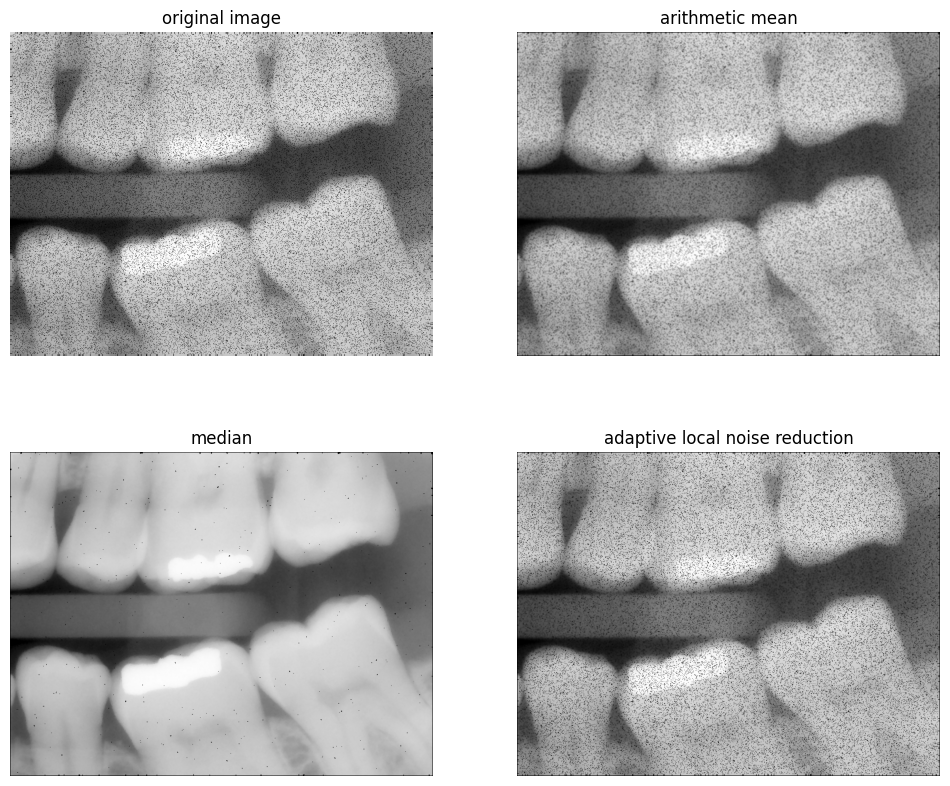

In [49]:
plt.figure(figsize=(12,10))
plt.subplot(221)
plt.imshow(f2,cmap='gray',aspect='equal', vmin=0, vmax=255)
plt.axis('off')
plt.title('original image')
plt.subplot(222)
plt.imshow(f2_mean,cmap='gray',aspect='equal', vmin=0, vmax=255)
plt.axis('off')
plt.title('arithmetic mean')
plt.subplot(223)
plt.imshow(f2_median,cmap='gray',aspect='equal', vmin=0, vmax=255)
plt.axis('off')
plt.title('median')
plt.subplot(224)
plt.imshow(f2_amean,cmap='gray',aspect='equal', vmin=0, vmax=255)
plt.axis('off')
plt.title('adaptive local noise reduction')
plt.show()

### 결과 분석

**1. 원본 noisy image 분석**

히스토그램에서 밝기 0에 몰려있고 255쪽은 몰려있지 않음
salt 없이 pepper noise만 있는 이미지

**2. Arithmetic Mean**

검은 점이 사라지지 않았고 밝기 0이 평균 계산으로 섞여 전체적으로 어두워짐

**3. Median**

median으로 극단의 값인 밝기 0이 제외되며 pepper가 잘 제거됨. 치아의 경계와 모양도 선명하게 보임

**4. Adaptive local noise reduction**

치아 사이의 띠의 표준편차를 계산해 잡음 표준편차를 30으로 둠. 밝은 부분에서는 분산이 크게 나와 필터가 점을 엣지로 판단해 보존해서 어두운 부분에서의 검은 점은 줄었지만 치아 같은 밝은 부분의 검은 점은 사라지지 않음

**5. 결론**

pepper noise가 있는 이미지에는 Median filter가 가장 적합함

- 복원된 f2를 그림파일로 저장하기

In [50]:
plt.imsave('denoised-dentalXray-mean.png',f2_mean,cmap='gray', vmin=0, vmax=255)
plt.imsave('denoised-dentalXray-median.png',f2_median,cmap='gray', vmin=0, vmax=255)
plt.imsave('denoised-dentalXray-adaptive.png',f2_amean,cmap='gray', vmin=0, vmax=255)